In [1]:
import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.ticker import PercentFormatter
import tensorflow as tf
from pathlib import Path
from tensorflow import keras
from keras import models, layers
from sklearn.metrics import f1_score, accuracy_score

In [2]:
def set_reproducibility(seed=42):
    # 1. Fijar semilla en Python core
    os.environ['PYTHONHASHSEED'] = str(seed)
    random.seed(seed)
    np.random.seed(seed)
    tf.random.set_seed(seed)
    keras.utils.set_random_seed(seed)
set_reproducibility()

In [3]:
current_dir = Path.cwd()
sl_results_path = str(current_dir.parent / 'ecpick/2L_results/result (2).csv')
tl_results_path = str(current_dir.parent / 'ecpick/3L_results/result (3).csv')

In [4]:
sl_results = pd.read_csv(sl_results_path)
tl_results = pd.read_csv(tl_results_path)
sl_results.columns = sl_results.columns.str.strip()
tl_results.columns = tl_results.columns.str.strip()

In [5]:
tl_results

,Seq ID,EC,Prob
0,seq_0,3.5.4.19,91.218918
1,seq_1,3.1.21.2,79.775795
2,seq_2,3.6.4.12,96.771385
3,seq_3,3.5.2.7,91.209503
4,seq_4,3.5.1.5,59.583153
...,...,...,...
2714,seq_3073,3.5.4.2,52.457733
2715,seq_3074,3.1.3.5,34.490093
2716,seq_3075,3.1.3.48,51.978485
2717,seq_3076,3.5.3.6,56.815739


In [6]:
sl_seq_ids = sl_results['Seq ID'].str.split('_').str[1].astype(np.int64).to_numpy().ravel()
tl_seq_ids = tl_results['Seq ID'].str.split('_').str[1].astype(np.int64).to_numpy().ravel()

sl_pred_classes = (sl_results['EC'].str.split('.').str[0].astype(np.int64) - 1).to_numpy()

tl_positive_ecs = {'3.2.1.14', '3.2.1.32', '3.2.1.200', '3.2.1.201'}
tl_pred_classes = tl_results['EC'].isin(tl_positive_ecs).astype(np.int64).to_numpy()

sl_preprocessed = np.column_stack((sl_seq_ids, sl_pred_classes))
tl_preprocessed = np.column_stack((tl_seq_ids, tl_pred_classes))

sl_preprocessed[:5], tl_preprocessed[:5]

(array([[0, 3],
        [1, 2],
        [2, 1],
        [4, 1],
        [5, 1]]),
 array([[0, 0],
        [1, 0],
        [2, 0],
        [3, 0],
        [4, 0]]))

In [ ]:
sl_emb_path = str(current_dir.parent / 'datasets/Second_Level/test_emb.npy')
sl_feat_path = str(current_dir.parent / 'datasets/Second_Level/test_feat.npy')
y_test_sl_path = str(current_dir.parent / 'datasets/Second_Level/y_test.npy')
tl_emb_path = str(current_dir.parent / 'datasets/pre_processed/test_emb.npy')
tl_feat_path = str(current_dir.parent / 'datasets/pre_processed/test_feat.npy')
y_test_tl_path = str(current_dir.parent / 'datasets/pre_processed/y_test.npy')
num_class = 7
protbert_embed_dim = 1024
features_dim = 887
latent_dim = 128
T = 20
S = 20
model_dir_sl = str(current_dir.parent / 'notebooks/2L_train/model.keras')
encoder_dir = str(current_dir.parent / 'models/vae_enc_smoteen.keras')
classifier_dir = str(current_dir.parent / 'models/vae_classifier_smoteen.keras')

In [8]:
test_emb_sl = np.load(sl_emb_path)
test_feat_sl = np.load(sl_feat_path)
y_test_sl = np.load(y_test_sl_path)
test_emb_tl = np.load(tl_emb_path)
test_feat_tl = np.load(tl_feat_path)
y_test_tl = np.load(y_test_tl_path)

In [9]:
@tf.function
def sampling_reparameterization(distribution_params) -> tf.Tensor:
    mean, log_var = distribution_params
    epsilon = tf.random.normal(shape=tf.shape(mean), mean=0., stddev=1.)
    z = mean + tf.exp(log_var / 2) * epsilon
    return z

@tf.function
def binary_entropy(p, eps=1e-7) -> tf.Tensor:
    p = tf.clip_by_value(p, eps, 1. - eps)
    return -(p * tf.math.log(p) + (1 - p) * tf.math.log(1 - p))

class UQ_VAE(models.Model):
    def __init__(self, encoder_dir, classifier_dir):
        super(UQ_VAE, self).__init__()
        self.encoder = models.load_model(encoder_dir)
        self.classifier = models.load_model(classifier_dir)
        self.logits_classifier = models.Model(inputs=self.classifier.input, outputs=[self.classifier.layers[-1].output, self.classifier.layers[-2].output])

    @tf.function
    def _mc_forward_pass(self, x, S):
        if self.encoder is None or self.classifier is None:
            raise ValueError("Los modelos encoder y classifier no han sido cargados correctamente.")
        mean, log_var = self.encoder(x, training=True)  # (B, 128)
        mean = tf.expand_dims(mean, axis=1)        # (B, 1, 128)
        log_var = tf.expand_dims(log_var, axis=1)  # (B, 1, 128)
        # Repetimos S veces
        mean = tf.repeat(mean, repeats=S, axis=1)      # (B, S, 128)
        log_var = tf.repeat(log_var, repeats=S, axis=1)
        z = sampling_reparameterization((mean, log_var))  # (B, S, 128)
        B = tf.shape(z)[0]
        z_flat = tf.reshape(z, (-1, 128))  # (B*S, 128)

        p, logits = self.logits_classifier(z_flat, training=True)  # (B*S, 1)
        p = tf.reshape(p, (B, S))               # (B, S)
        logits = tf.reshape(logits, (B, S))     # (B, S)
        p_mean = tf.reduce_mean(p, axis=1)      # (B,)
        logits_mean = tf.reduce_mean(logits, axis=1)
        u_aleatoric = tf.reduce_mean(binary_entropy(p), axis=1)  # (B,)
        return p_mean, logits_mean, u_aleatoric
    
    def predict_with_uncertainty(self, dataset, T=20, S=20):
        all_p_mean = []
        all_logits_mean = []
        all_u_aleatoric = []
        for x_batch in dataset:
            batch_p = []
            batch_logit = []
            batch_u_a = []
            for _ in range(T):
                p_mean_t, logits_mean_t, u_a_t = self._mc_forward_pass(x_batch, S)
                batch_p.append(p_mean_t)
                batch_logit.append(logits_mean_t)
                batch_u_a.append(u_a_t)

            # Stack epistémico
            batch_p = tf.stack(batch_p, axis=0)        # (T, B)
            batch_logit = tf.stack(batch_logit, axis=0) # (T, B)
            batch_u_a = tf.stack(batch_u_a, axis=0)    # (T, B)

            u_aleatoric = tf.reduce_mean(batch_u_a, axis=0)  # (B,)
            logits_mean = tf.reduce_mean(batch_logit, axis=0)
            p_marginal = tf.reduce_mean(batch_p, axis=0)     
            u_total = binary_entropy(p_marginal)              
            u_epistemic = u_total - u_aleatoric               

            all_p_mean.append(p_marginal)
            all_logits_mean.append(logits_mean)
            all_u_aleatoric.append((u_total, u_aleatoric, u_epistemic))

        return (
            tf.concat(all_p_mean, axis=0),
            tf.concat(all_logits_mean, axis=0),
            tuple(tf.concat(x, axis=0) for x in zip(*all_u_aleatoric))
        )
    

@tf.function
def categorical_entropy(probs, axis=-1, eps=1e-8, from_logits=False) -> tf.Tensor:
    x = tf.convert_to_tensor(probs, dtype=tf.float32)
    if from_logits:
        x = tf.nn.softmax(x, axis=axis)
    x = tf.clip_by_value(x, eps, 1.0)
    entropy = -tf.reduce_sum(x * tf.math.log(x), axis=axis)
    return entropy

class UQ_Classifier(models.Model):
    def __init__(self, model_dir):
        super(UQ_Classifier, self).__init__()
        self.model = models.load_model(model_dir)
        self.logits_model = models.Model(inputs=self.model.input, outputs=self.model.layers[-2].output)
    def _tensor_key(self, tensor):
        return getattr(tensor, 'name', str(tensor))
    @tf.function
    def _mc_forward_pass(self, x):
        if self.model is None:
            raise ValueError("El modelo no se cargó correctamente.")
        layer_outputs = {}
        model_inputs = x if isinstance(x, (tuple, list)) else (x,)
        for tensor, value in zip(self.model.inputs, model_inputs):
            layer_outputs[self._tensor_key(tensor)] = value
        for layer in self.model.layers:
            if isinstance(layer, layers.InputLayer):
                continue
            inbound = layer.input
            if isinstance(inbound, (list, tuple)):
                layer_input = [layer_outputs[self._tensor_key(t)] for t in inbound]
            else:
                layer_input = layer_outputs[self._tensor_key(inbound)]
            if isinstance(layer, layers.Dropout):
                layer_output = layer(layer_input, training=True)
            elif isinstance(layer, (layers.BatchNormalization, layers.GaussianNoise)):
                layer_output = layer(layer_input, training=False)
            else:
                layer_output = layer(layer_input)
            outbound = layer.output
            if isinstance(outbound, (list, tuple)):
                for tensor, value in zip(outbound, layer_output):
                    layer_outputs[self._tensor_key(tensor)] = value
            else:
                layer_outputs[self._tensor_key(outbound)] = layer_output
        logits = layer_outputs[self._tensor_key(self.model.layers[-2].output)]
        p = tf.nn.softmax(logits, axis=-1)
        return p, logits
    
    def predict_with_uncertainty(self, dataset, T=50):
        all_p_mean = []
        all_logits_mean = []
        all_u = []
        for x_batch in dataset:
            batch_p = []
            batch_logit = []
            for _ in range(T):
                p_mean_t, logits_t= self._mc_forward_pass(x_batch)
                batch_p.append(p_mean_t)
                batch_logit.append(logits_t)

            # Stack epistémico
            batch_p = tf.stack(batch_p, axis=0)        # (T, B, num_class)
            batch_logit = tf.stack(batch_logit, axis=0) # (T, B, num_class)
            #temp_batch_p = tf.reshape(batch_p, (-1, T, num_class))
            u_aleatoric = tf.reduce_mean(categorical_entropy(batch_p), axis=0)
            u_aleatoric = tf.reshape(u_aleatoric, (-1, 1))
            p_marginal = tf.reduce_mean(batch_p, axis=0)

            mean_logits = tf.reduce_mean(batch_logit, axis=0)  
            u_total = categorical_entropy(p_marginal)
            u_total = tf.reshape(u_total, (-1, 1))          
            u_epistemic = u_total - u_aleatoric               

            all_p_mean.append(p_marginal)
            all_u.append((u_total, u_aleatoric, u_epistemic))
            all_logits_mean.append(mean_logits)

        outputs = (
            tf.concat(all_p_mean, axis=0), 
            tf.concat(all_logits_mean, axis=0),
            tuple(tf.concat(x, axis=0) for x in zip(*all_u))
        )
        return outputs

In [10]:
uq_sl = UQ_Classifier(model_dir_sl)
uq_tl = UQ_VAE(encoder_dir, classifier_dir)

In [ ]:
""" Ejemplo de uso:
test_sl = tf.data.Dataset.from_tensor_slices(
    (test_emb_sl.astype('float32'), test_feat_sl.astype('float32'))
).batch(64)
test_tl = tf.data.Dataset.from_tensor_slices(
    (test_emb_tl.astype('float32'), test_feat_tl.astype('float32'))
).batch(64)

predictions_sl, logits_sl, uncertainties_sl = uq_sl.predict_with_uncertainty(test_sl)
predictions_tl, logits_tl, uncertainties_tl = uq_tl.predict_with_uncertainty(test_tl)
predictions_sl = predictions_sl.numpy()
predictions_tl = predictions_tl.numpy()
u_total_sl = uncertainties_sl[0].numpy()
u_total_tl = uncertainties_tl[0].numpy()
"""

In [11]:
batch_size = 64

test_sl = tf.data.Dataset.from_tensor_slices(
    (test_emb_sl.astype('float32'), test_feat_sl.astype('float32'))
).batch(batch_size)
test_tl = tf.data.Dataset.from_tensor_slices(
    (test_emb_tl.astype('float32'), test_feat_tl.astype('float32'))
).batch(batch_size)

predictions_sl, logits_sl, uncertainties_sl = uq_sl.predict_with_uncertainty(test_sl, T=T)
predictions_tl, logits_tl, uncertainties_tl = uq_tl.predict_with_uncertainty(test_tl, T=T, S=S)

predictions_sl = predictions_sl.numpy()
logits_sl = logits_sl.numpy()
u_total_sl, u_aleatoric_sl, u_epistemic_sl = [u.numpy().reshape(-1) for u in uncertainties_sl]
sl_model_pred_classes = predictions_sl.argmax(axis=1).astype(np.int64)
sl_model_pred_probs = predictions_sl[np.arange(len(predictions_sl)), sl_model_pred_classes]

predictions_tl = predictions_tl.numpy().reshape(-1)
logits_tl = logits_tl.numpy().reshape(-1)
u_total_tl, u_aleatoric_tl, u_epistemic_tl = [u.numpy().reshape(-1) for u in uncertainties_tl]
tl_model_pred_classes = (predictions_tl >= 0.5).astype(np.int64)
tl_model_pred_probs = np.where(tl_model_pred_classes == 1, predictions_tl, 1.0 - predictions_tl)

sl_inference = pd.DataFrame({
    'seq_id': np.arange(len(test_emb_sl)),
    'pred_class': sl_model_pred_classes,
    'pred_prob': sl_model_pred_probs,
    'u_total': u_total_sl,
    'u_aleatoric': u_aleatoric_sl,
    'u_epistemic': u_epistemic_sl,
}).sort_values('u_total', ascending=True)

tl_inference = pd.DataFrame({
    'seq_id': np.arange(len(test_emb_tl)),
    'pred_class': tl_model_pred_classes,
    'pred_prob': tl_model_pred_probs,
    'u_total': u_total_tl,
    'u_aleatoric': u_aleatoric_tl,
    'u_epistemic': u_epistemic_tl,
}).sort_values('u_total', ascending=True)

sl_inference.head(), tl_inference.head()

(       seq_id  pred_class  pred_prob   u_total  u_aleatoric  u_epistemic
 15066   15066           2        1.0  0.000001     0.000001          0.0
 15097   15097           1        1.0  0.000001     0.000001          0.0
 15093   15093           4        1.0  0.000001     0.000001          0.0
 15193   15193           1        1.0  0.000001     0.000001          0.0
 15192   15192           4        1.0  0.000001     0.000001          0.0,
       seq_id  pred_class  pred_prob   u_total  u_aleatoric   u_epistemic
 73        73           0        1.0  0.000002     0.000002 -2.045621e-07
 70        70           0        1.0  0.000002     0.000002  0.000000e+00
 2267    2267           0        1.0  0.000002     0.000002 -6.496464e-08
 3050    3050           0        1.0  0.000002     0.000002  0.000000e+00
 3048    3048           0        1.0  0.000002     0.000002 -3.479976e-07)

In [20]:
def to_label_vector(y):
    y = np.asarray(y)
    if y.ndim > 1 and y.shape[-1] > 1:
        return y.argmax(axis=1).astype(np.int64)
    return y.reshape(-1).astype(np.int64)

def macro_f1_prefix_curve(y_true, y_pred, uncertainty, labels=None):
    y_true = np.asarray(y_true, dtype=np.int64)
    y_pred = np.asarray(y_pred, dtype=np.int64)
    if labels is None:
        labels = np.unique(np.concatenate([y_true, y_pred]))
    labels = np.asarray(labels, dtype=np.int64)
    label_to_index = {label: idx for idx, label in enumerate(labels)}

    order = np.argsort(uncertainty, kind='mergesort')
    y_true_sorted = y_true[order]
    y_pred_sorted = y_pred[order]
    n = len(y_true_sorted)
    coverage = np.arange(1, n + 1, dtype=np.float64) / n
    f1_values = np.empty(n, dtype=np.float64)
    tp = np.zeros(len(labels), dtype=np.int64)
    fp = np.zeros(len(labels), dtype=np.int64)
    fn = np.zeros(len(labels), dtype=np.int64)

    for i, (yt, yp) in enumerate(zip(y_true_sorted, y_pred_sorted)):
        yt_idx = label_to_index[yt]
        yp_idx = label_to_index[yp]
        if yt_idx == yp_idx:
            tp[yt_idx] += 1
        else:
            fp[yp_idx] += 1
            fn[yt_idx] += 1

        denom = 2 * tp + fp + fn
        per_class_f1 = np.divide(
            2 * tp,
            denom,
            out=np.zeros_like(denom, dtype=np.float64),
            where=denom > 0,
        )
        active = denom > 0
        f1_values[i] = per_class_f1[active].mean() if np.any(active) else 0.0

    return {
        'order': order,
        'coverage': coverage,
        'f1': f1_values,
    }

def binary_positive_f1_prefix_curve(y_true, y_pred, uncertainty, pos_label=1):
    order = np.argsort(uncertainty, kind='mergesort')
    y_true_sorted = y_true[order]
    y_pred_sorted = y_pred[order]
    n = len(y_true_sorted)
    coverage = np.arange(1, n + 1, dtype=np.float64) / n
    f1_values = np.empty(n, dtype=np.float64)
    tp = 0
    fp = 0
    fn = 0

    for i, (yt, yp) in enumerate(zip(y_true_sorted, y_pred_sorted)):
        if yp == pos_label and yt == pos_label:
            tp += 1
        elif yp == pos_label and yt != pos_label:
            fp += 1
        elif yp != pos_label and yt == pos_label:
            fn += 1

        denom = 2 * tp + fp + fn
        f1_values[i] = 0.0 if denom == 0 else (2 * tp) / denom

    return {
        'order': order,
        'coverage': coverage,
        'f1': f1_values,
    }

def curve_point_at_count(curve, count):
    idx = max(0, min(int(count), len(curve['coverage'])) - 1)
    return curve['coverage'][idx], curve['f1'][idx]

def plot_coverage_f1(ax, curve, coverage_ref, f1_ref, f1_ours_ref, title, label, metric_label='F1 macro'):
    ax.plot(curve['coverage'], curve['f1'], color='#0B6E4F', linewidth=2.5, label=f'Curva de rendimiento del {label}')
    ax.fill_between(curve['coverage'], curve['f1'], color='#0B6E4F', alpha=0.10)
    ax.axvline(coverage_ref, color='#D95F02', linestyle='--', linewidth=1.6, alpha=0.9)
    ax.scatter([coverage_ref], [f1_ours_ref], color='#1F77B4', s=90, zorder=5, label=f'{label} misma cobertura')
    ax.scatter([coverage_ref], [f1_ref], color='#D95F02', s=90, marker='D', zorder=6, label='ECPICK selectivo')
    ax.annotate(f'{f1_ours_ref:.3f}', (coverage_ref, f1_ours_ref), textcoords='offset points', xytext=(8, 8), fontsize=10, color='#1F77B4')
    ax.annotate(f'{f1_ref:.3f}', (coverage_ref, f1_ref), textcoords='offset points', xytext=(8, -16), fontsize=10, color='#D95F02')
    ax.set_title(title, fontsize=14, weight='bold')
    ax.set_xlabel('Cobertura')
    ax.set_ylabel(metric_label)
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1.02)
    ax.xaxis.set_major_formatter(PercentFormatter(1.0))
    ax.grid(True, alpha=0.25)
    ax.legend(loc='lower right', frameon=True)


In [13]:
sl_true_all = to_label_vector(y_test_sl)
tl_true_all = to_label_vector(y_test_tl)

sl_true_ecpick = sl_true_all[sl_seq_ids]
tl_true_ecpick = tl_true_all[tl_seq_ids]

sl_coverage_ecpick = len(sl_preprocessed) / len(sl_true_all)
tl_coverage_ecpick = len(tl_preprocessed) / len(tl_true_all)

sl_f1_ecpick = f1_score(sl_true_ecpick, sl_pred_classes, average='macro', zero_division=0)
tl_f1_ecpick = f1_score(tl_true_ecpick, tl_pred_classes, average='macro', zero_division=0)
tl_f1_ecpick_positive = f1_score(tl_true_ecpick, tl_pred_classes, average='binary', zero_division=0)

sl_curve = macro_f1_prefix_curve(sl_true_all, sl_model_pred_classes, u_total_sl, labels=np.arange(predictions_sl.shape[1]))
tl_curve = macro_f1_prefix_curve(tl_true_all, tl_model_pred_classes, u_total_tl, labels=np.array([0, 1]))
tl_curve_positive = binary_positive_f1_prefix_curve(tl_true_all, tl_model_pred_classes, u_total_tl)

sl_curve_df = pd.DataFrame({'coverage': sl_curve['coverage'], 'f1_macro': sl_curve['f1']})
tl_curve_df = pd.DataFrame({
    'coverage': tl_curve['coverage'],
    'f1_macro': tl_curve['f1'],
    'f1_positive': tl_curve_positive['f1'],
})

sl_cov_match, sl_f1_ours_at_ecpick = curve_point_at_count(sl_curve, len(sl_preprocessed))
tl_cov_match, tl_f1_ours_at_ecpick = curve_point_at_count(tl_curve, len(tl_preprocessed))

comparison_summary = pd.DataFrame([
    {
        'Nivel': '2L - EC principal',
        'Cobertura ECPICK': sl_coverage_ecpick,
        'Metrica': 'F1 macro',
        'F1 ECPICK': sl_f1_ecpick,
        'F1 Clasificador 2L misma cobertura': sl_f1_ours_at_ecpick,
        'Delta F1': sl_f1_ours_at_ecpick - sl_f1_ecpick,
    },
    {
        'Nivel': '3L - G18/GH19 vs resto',
        'Cobertura ECPICK': tl_coverage_ecpick,
        'Metrica': 'F1 macro',
        'F1 ECPICK': tl_f1_ecpick,
        'F1 MVAE 3L misma cobertura': tl_f1_ours_at_ecpick,
        'Delta F1': tl_f1_ours_at_ecpick - tl_f1_ecpick,
    },
])

comparison_summary.round(4)

,Nivel,Cobertura ECPICK,Metrica,F1 ECPICK,F1 Clasificador 2L misma cobertura,Delta F1,F1 MVAE 3L misma cobertura
0,2L - EC principal,0.9449,F1 macro,0.9843,0.9693,-0.0150,NaN
1,3L - G18/GH19 vs resto,0.8831,F1 macro,0.9934,NaN,0.0066,1.0


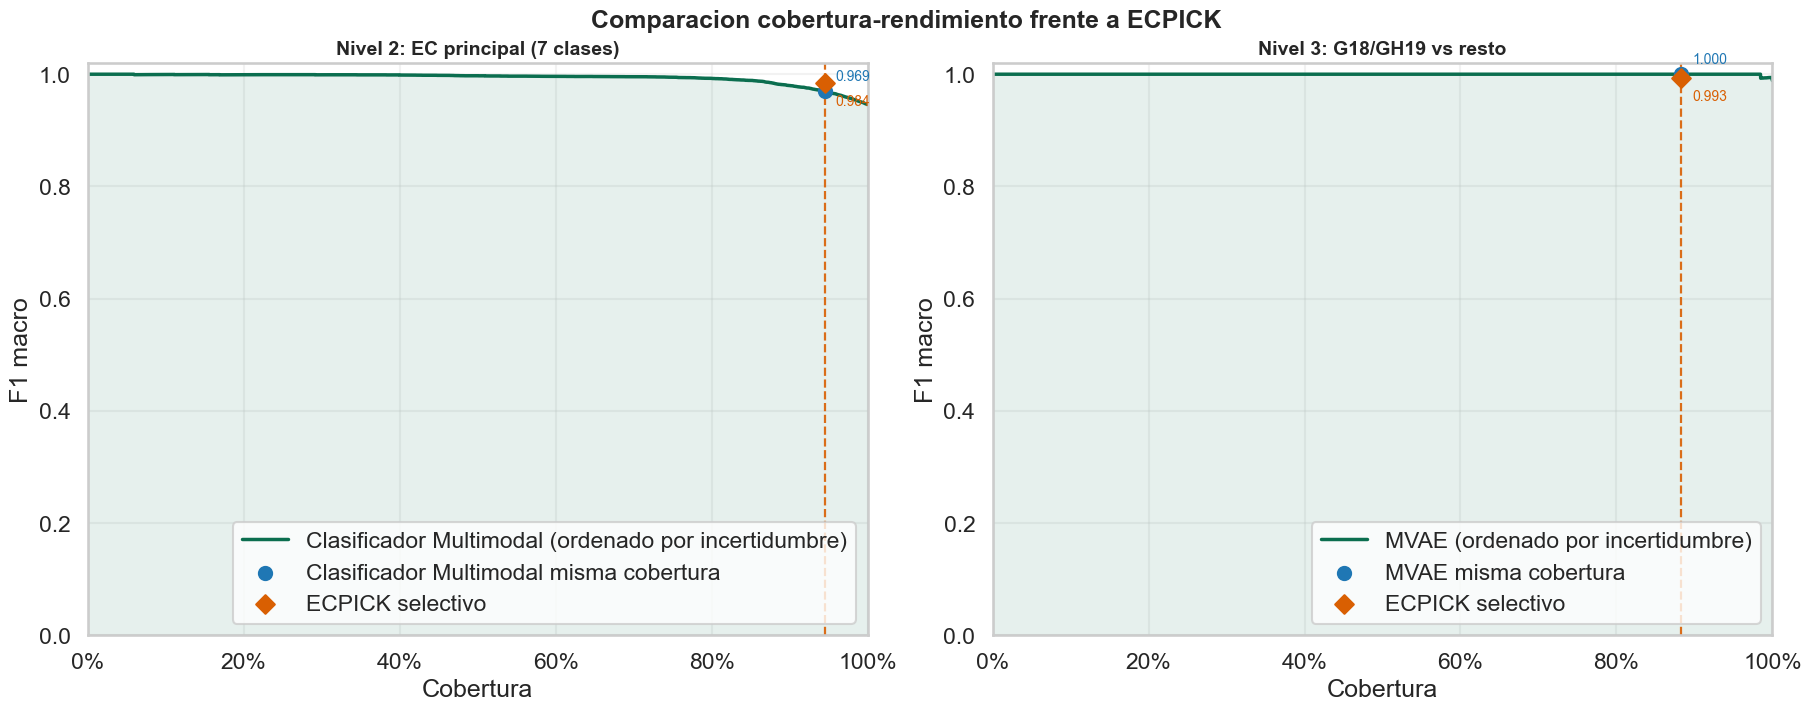

In [14]:
sns.set_theme(style='whitegrid', context='talk')

fig, axes = plt.subplots(1, 2, figsize=(18, 7), constrained_layout=True)

plot_coverage_f1(
    axes[0],
    sl_curve,
    sl_cov_match,
    sl_f1_ecpick,
    sl_f1_ours_at_ecpick,
    'Nivel 2: EC principal (7 clases)',
    'Clasificador Multimodal',
    metric_label='F1 macro',
)

plot_coverage_f1(
    axes[1],
    tl_curve,
    tl_cov_match,
    tl_f1_ecpick,
    tl_f1_ours_at_ecpick,
    'Nivel 3: G18/GH19 vs resto',
    'MVAE',
    metric_label='F1 macro',
)

fig.suptitle('Comparacion cobertura-rendimiento frente a ECPICK', fontsize=18, weight='bold')
plt.show()

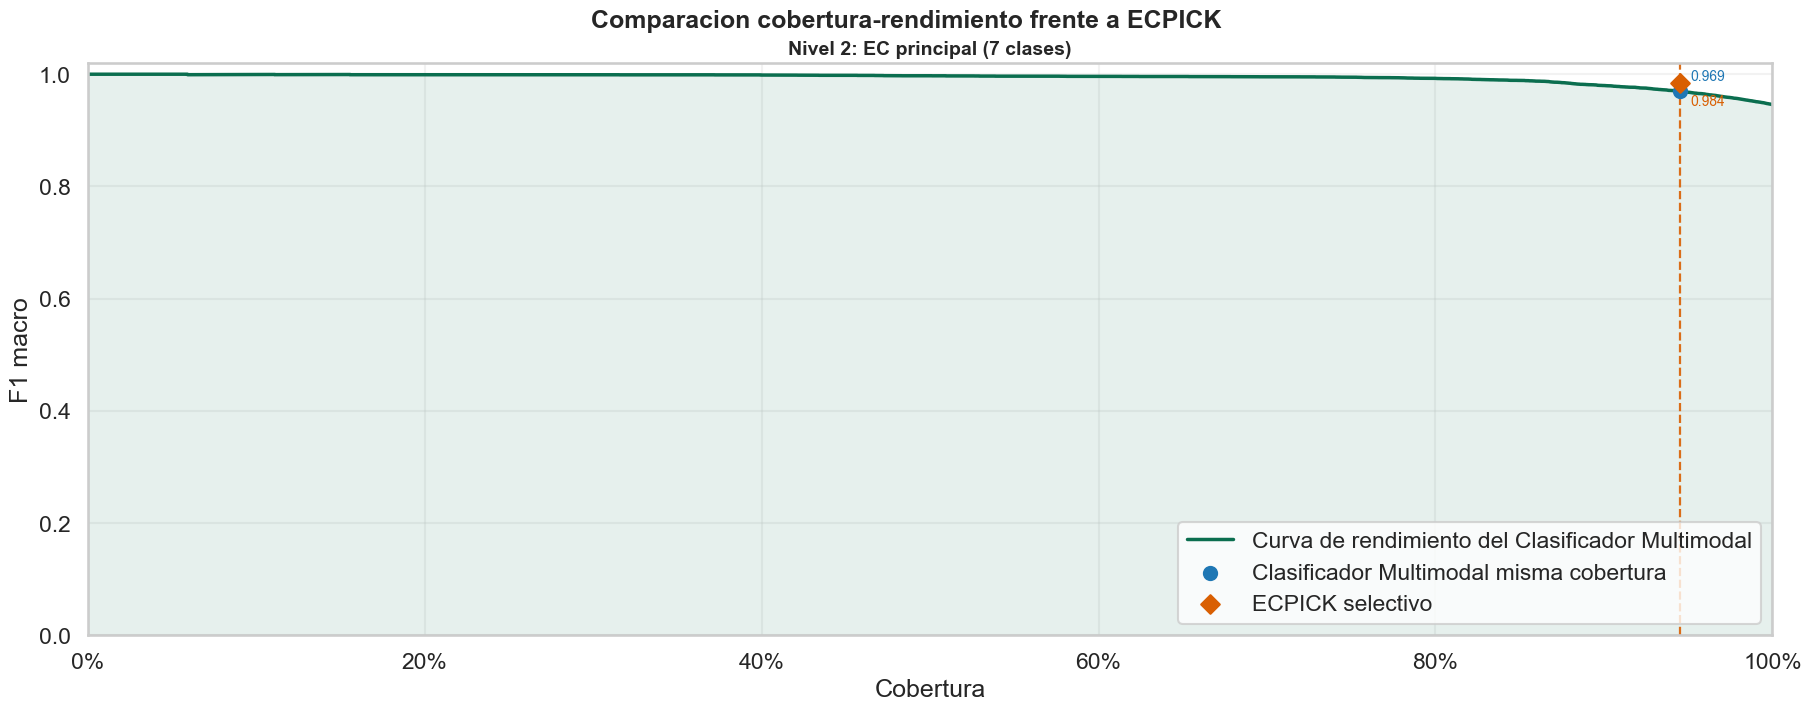

In [21]:
fig, axes = plt.subplots(1, 1, figsize=(18, 7), constrained_layout=True)

plot_coverage_f1(
    axes,
    sl_curve,
    sl_cov_match,
    sl_f1_ecpick,
    sl_f1_ours_at_ecpick,
    'Nivel 2: EC principal (7 clases)',
    'Clasificador Multimodal',
    metric_label='F1 macro',
)
fig.suptitle('Comparacion cobertura-rendimiento frente a ECPICK', fontsize=18, weight='bold')
plt.show()

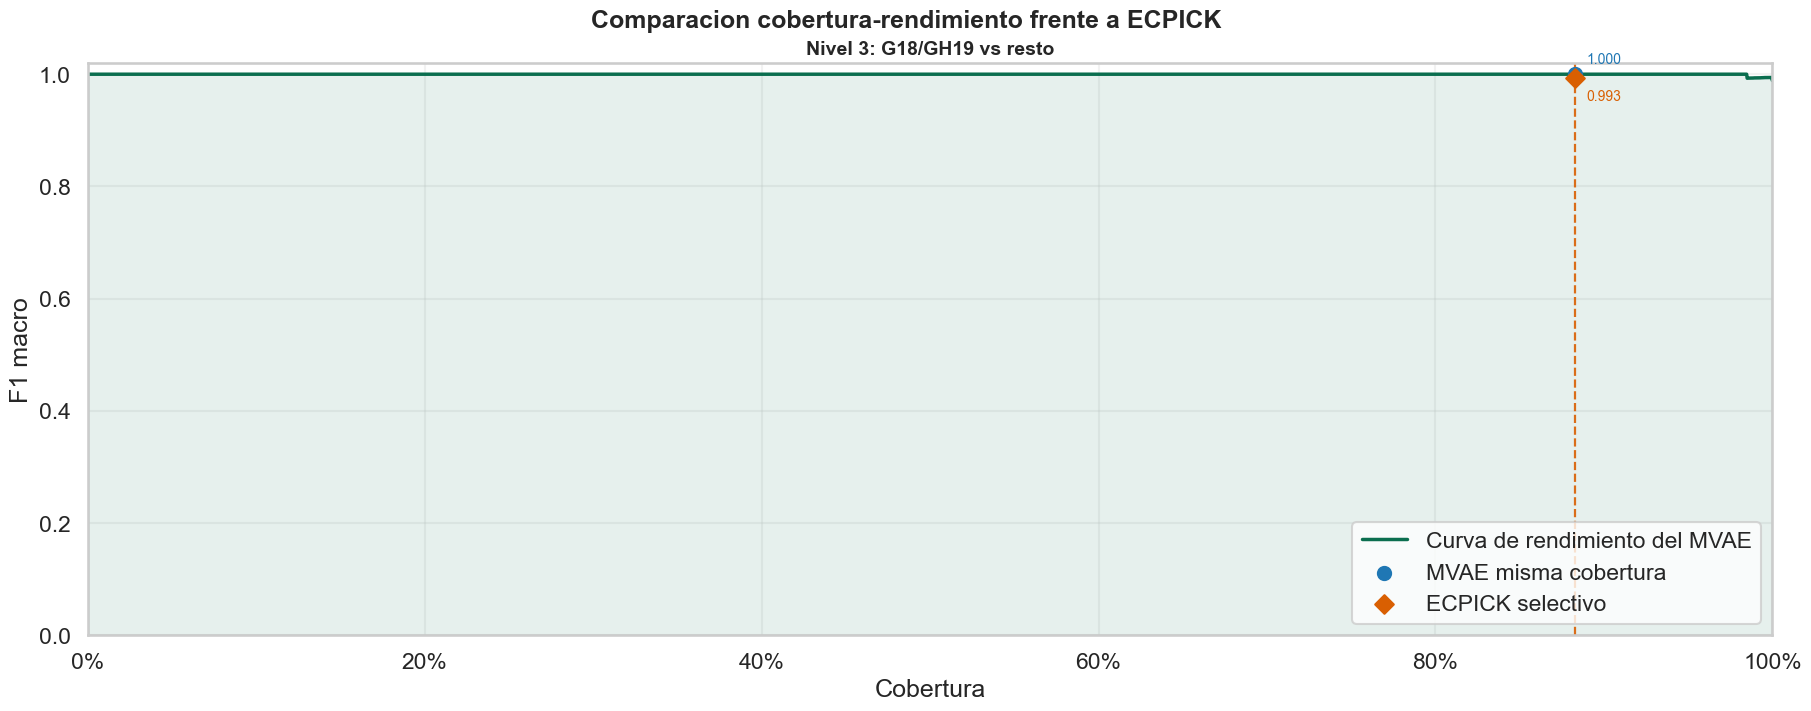

In [22]:
fig, axes = plt.subplots(1, 1, figsize=(18, 7), constrained_layout=True)

plot_coverage_f1(
    axes,
    tl_curve,
    tl_cov_match,
    tl_f1_ecpick,
    tl_f1_ours_at_ecpick,
    'Nivel 3: G18/GH19 vs resto',
    'MVAE',
    metric_label='F1 macro',
)
fig.suptitle('Comparacion cobertura-rendimiento frente a ECPICK', fontsize=18, weight='bold')
plt.show()